# Ola Ride Insights: Data Cleaning & EDA

**Domain:** Ride-sharing & mobility analytics
**Data:** 103,024 Ola bookings from Bengaluru, 1 to 31 July 2024 (`OLA_DataSet.xlsx`, sheet *July*)

In this notebook I go through the raw booking data, clean it, and look for patterns that answer the four business questions from the brief:

1. When is demand highest, and how should drivers be allocated?
2. How do customers behave (vehicle choice, payment, ratings)?
3. What does pricing look like?
4. Is there anything in the data that looks unusual or suspicious?

The cleaned file produced at the end (`data/ola_rides_clean.csv`) is what the SQL queries, the Power BI report and the Streamlit app all use.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", 40)
sns.set_theme(style="whitegrid", font_scale=0.95)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

# one colour per job: blue for single-series charts, a fixed order for categories
BLUE = "#2a78d6"
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6"]

## 1. Load the data

In [2]:
xls = pd.ExcelFile("../data/raw/OLA_DataSet.xlsx")
print("Sheets in the file:", xls.sheet_names)

raw = pd.read_excel(xls, sheet_name="July")
print("Shape:", raw.shape)
raw.head()

Sheets in the file: ['July', 'Sheet1', 'Sheet2']


Shape: (103024, 20)


,Date,Time,Booking_ID,Booking_Status,Customer_ID,Vehicle_Type,Pickup_Location,Drop_Location,V_TAT,C_TAT,Canceled_Rides_by_Customer,Canceled_Rides_by_Driver,Incomplete_Rides,Incomplete_Rides_Reason,Booking_Value,Payment_Method,Ride_Distance,Driver_Ratings,Customer_Rating,Vehicle Images
0,2024-07-26 14:00:00,14:00:00,CNR7153255142,Canceled by Driver,CID713523,Prime Sedan,Tumkur Road,RT Nagar,NaN,NaN,NaN,Personal & Car related issue,NaN,NaN,444,NaN,0,NaN,NaN,https://cdn-icons-png.flaticon.com/128/14183/1...
1,2024-07-25 22:20:00,22:20:00,CNR2940424040,Success,CID225428,Bike,Magadi Road,Varthur,203.0,30.0,NaN,NaN,No,NaN,158,Cash,13,4.1,4.0,https://cdn-icons-png.flaticon.com/128/9983/99...
2,2024-07-30 19:59:00,19:59:00,CNR2982357879,Success,CID270156,Prime SUV,Sahakar Nagar,Varthur,238.0,130.0,NaN,NaN,No,NaN,386,UPI,40,4.2,4.8,https://cdn-icons-png.flaticon.com/128/9983/99...
3,2024-07-22 03:15:00,03:15:00,CNR2395710036,Canceled by Customer,CID581320,eBike,HSR Layout,Vijayanagar,NaN,NaN,Driver is not moving towards pickup location,NaN,NaN,NaN,384,NaN,0,NaN,NaN,https://cdn-icons-png.flaticon.com/128/6839/68...
4,2024-07-02 09:02:00,09:02:00,CNR1797421769,Success,CID939555,Mini,Rajajinagar,Chamarajpet,252.0,80.0,NaN,NaN,No,NaN,822,Credit Card,45,4.0,3.0,https://cdn-icons-png.flaticon.com/128/3202/32...


`Sheet1` and `Sheet2` are only scratch pivots and an icon lookup, so all the ride data comes from the **July** sheet.

## 2. Understand the structure

In [3]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 103024 entries, 0 to 103023
Data columns (total 20 columns):
 #   Column                      Non-Null Count   Dtype         
---  ------                      --------------   -----         
 0   Date                        103024 non-null  datetime64[us]
 1   Time                        103024 non-null  object        
 2   Booking_ID                  103024 non-null  str           
 3   Booking_Status              103024 non-null  str           
 4   Customer_ID                 103024 non-null  str           
 5   Vehicle_Type                103024 non-null  str           
 6   Pickup_Location             103024 non-null  str           
 7   Drop_Location               103024 non-null  str           
 8   V_TAT                       63967 non-null   float64       
 9   C_TAT                       63967 non-null   float64       
 10  Canceled_Rides_by_Customer  10499 non-null   str           
 11  Canceled_Rides_by_Driver    18434 non-null   str  

In [4]:
# how much is missing in each column
missing = raw.isna().sum().to_frame("missing")
missing["missing_%"] = (missing["missing"] / len(raw) * 100).round(1)
missing[missing["missing"] > 0]

,missing,missing_%
V_TAT,39057,37.9
C_TAT,39057,37.9
Canceled_Rides_by_Customer,92525,89.8
Canceled_Rides_by_Driver,84590,82.1
Incomplete_Rides,39057,37.9
Incomplete_Rides_Reason,99098,96.2
Payment_Method,39057,37.9
Driver_Ratings,39057,37.9
Customer_Rating,39057,37.9


In [5]:
# missing values line up exactly with the booking status
raw.groupby("Booking_Status")[["Payment_Method", "Driver_Ratings", "V_TAT",
                               "Canceled_Rides_by_Customer", "Canceled_Rides_by_Driver"]].apply(lambda g: g.isna().mean().round(2))

,Payment_Method,Driver_Ratings,V_TAT,Canceled_Rides_by_Customer,Canceled_Rides_by_Driver
Booking_Status,,,,,
Canceled by Customer,1.0,1.0,1.0,0.0,1.0
Canceled by Driver,1.0,1.0,1.0,1.0,0.0
Driver Not Found,1.0,1.0,1.0,1.0,1.0
Success,0.0,0.0,0.0,1.0,1.0


**What this tells me:** the blanks are not lost data. Payment method, ratings and the two TAT columns only exist when a ride was completed, and the cancel reason columns only exist for cancelled rides. So I will **not** fill them with 0 or the mean. Doing that would invent ratings for rides that never happened and drag every average down. They stay as blanks (NULL in SQL).

In [6]:
for col in ["Booking_Status", "Vehicle_Type", "Payment_Method", "Incomplete_Rides", "Incomplete_Rides_Reason"]:
    print(raw[col].value_counts(dropna=False), "\n")

Booking_Status
Success                 63967
Canceled by Driver      18434
Canceled by Customer    10499
Driver Not Found        10124
Name: count, dtype: int64 

Vehicle_Type
Prime Sedan    14877
eBike          14816
Auto           14755
Prime Plus     14707
Bike           14662
Prime SUV      14655
Mini           14552
Name: count, dtype: int64 

Payment_Method
NaN            39057
Cash           35022
UPI            25881
Credit Card     2435
Debit Card       629
Name: count, dtype: int64 

Incomplete_Rides
No     60041
NaN    39057
Yes     3926
Name: count, dtype: int64 

Incomplete_Rides_Reason
NaN                  99098
Customer Demand       1601
Vehicle Breakdown     1591
Other Issue            734
Name: count, dtype: int64 



In [7]:
print("Duplicate Booking IDs:", raw["Booking_ID"].duplicated().sum())
print("Unique customers     :", raw["Customer_ID"].nunique())
print("Pickup locations     :", raw["Pickup_Location"].nunique())
print("Date range           :", raw["Date"].min(), "to", raw["Date"].max())
raw.describe().round(2)

Duplicate Booking IDs: 0
Unique customers     : 94544
Pickup locations     : 50
Date range           : 2024-07-01 00:00:00 to 2024-07-31 23:58:00


,Date,V_TAT,C_TAT,Booking_Value,Ride_Distance,Driver_Ratings,Customer_Rating
count,103024,63967.00,63967.00,103024.00,103024.00,63967.00,63967.00
mean,2024-07-16 11:31:38.879678,170.88,84.87,548.75,14.19,4.00,4.00
min,2024-07-01 00:00:00,35.00,25.00,100.00,0.00,3.00,3.00
25%,2024-07-08 18:41:00,98.00,55.00,242.00,0.00,3.50,3.50
50%,2024-07-16 11:23:00,168.00,85.00,386.00,8.00,4.00,4.00
75%,2024-07-24 05:18:00,238.00,115.00,621.00,26.00,4.50,4.50
max,2024-07-31 23:58:00,308.00,145.00,2999.00,49.00,5.00,5.00
std,NaN,80.80,36.01,536.54,15.78,0.58,0.58


## 3. Clean and prepare

In [8]:
df = raw.copy()

# column names: no spaces
df.columns = [c.strip().replace(" ", "_") for c in df.columns]

# trim stray spaces in text columns
for col in df.select_dtypes(include=["object", "string"]).columns:
    df[col] = df[col].astype("string").str.strip()

# 'eBike' -> 'E-Bike' to match the dashboard template
df["Vehicle_Type"] = df["Vehicle_Type"].replace({"eBike": "E-Bike"})

# Date already holds the time, so build all time parts from it
df["Booking_DateTime"] = pd.to_datetime(df["Date"])
df["Ride_Date"] = df["Booking_DateTime"].dt.date
df["Ride_Time"] = df["Booking_DateTime"].dt.strftime("%H:%M")
df["Ride_Hour"] = df["Booking_DateTime"].dt.hour
df["Day_Name"] = df["Booking_DateTime"].dt.day_name()

def time_band(h):
    if h < 6:  return "Late Night (0-5)"
    if h < 12: return "Morning (6-11)"
    if h < 17: return "Afternoon (12-16)"
    if h < 21: return "Evening (17-20)"
    return "Night (21-23)"

df["Time_Band"] = df["Ride_Hour"].apply(time_band)

# who ended the booking
df["Cancelled_By"] = df["Booking_Status"].map({
    "Success": "Completed", "Canceled by Customer": "Customer",
    "Canceled by Driver": "Driver", "Driver Not Found": "No Driver"})

# one reason column, whoever cancelled
df["Cancel_Reason"] = df["Canceled_Rides_by_Customer"].fillna(df["Canceled_Rides_by_Driver"])
df.loc[df["Booking_Status"] == "Driver Not Found", "Cancel_Reason"] = "Driver Not Found"

# revenue only counts for rides that happened
df["Revenue"] = np.where(df["Booking_Status"] == "Success", df["Booking_Value"], 0)

df[["Booking_DateTime", "Ride_Hour", "Day_Name", "Time_Band", "Cancelled_By", "Cancel_Reason", "Revenue"]].head()

,Booking_DateTime,Ride_Hour,Day_Name,Time_Band,Cancelled_By,Cancel_Reason,Revenue
0,2024-07-26 14:00:00,14,Friday,Afternoon (12-16),Driver,Personal & Car related issue,0
1,2024-07-25 22:20:00,22,Thursday,Night (21-23),Completed,<NA>,158
2,2024-07-30 19:59:00,19,Tuesday,Evening (17-20),Completed,<NA>,386
3,2024-07-22 03:15:00,3,Monday,Late Night (0-5),Customer,Driver is not moving towards pickup location,0
4,2024-07-02 09:02:00,9,Tuesday,Morning (6-11),Completed,<NA>,822


In [9]:
keep = ["Booking_ID", "Ride_Date", "Ride_Time", "Ride_Hour", "Day_Name", "Time_Band",
        "Booking_Status", "Cancelled_By", "Customer_ID", "Vehicle_Type", "Pickup_Location",
        "Drop_Location", "V_TAT", "C_TAT", "Canceled_Rides_by_Customer", "Canceled_Rides_by_Driver",
        "Cancel_Reason", "Incomplete_Rides", "Incomplete_Rides_Reason", "Booking_Value", "Revenue",
        "Payment_Method", "Ride_Distance", "Driver_Ratings", "Customer_Rating"]

clean = df.sort_values("Booking_DateTime")[keep]
clean.to_csv("../data/ola_rides_clean.csv", index=False)
print("Saved clean file:", clean.shape)

Saved clean file: (103024, 25)


The same steps are saved as a script in `clean_data.py`, so the clean file can be rebuilt in one command.

## 4. Overall picture

In [10]:
success = df[df["Booking_Status"] == "Success"]

kpis = {
    "Total bookings": len(df),
    "Successful rides": len(success),
    "Success rate %": round(len(success) / len(df) * 100, 1),
    "Revenue (Rs)": int(success["Booking_Value"].sum()),
    "Avg fare per ride (Rs)": round(success["Booking_Value"].mean(), 1),
    "Avg distance per ride (km)": round(success["Ride_Distance"].mean(), 1),
    "Avg driver rating": round(success["Driver_Ratings"].mean(), 2),
    "Avg customer rating": round(success["Customer_Rating"].mean(), 2),
}
pd.Series(kpis, name="value").to_frame()

,value
Total bookings,103024.0
Successful rides,63967.0
Success rate %,62.1
Revenue (Rs),35080467.0
Avg fare per ride (Rs),548.4
Avg distance per ride (km),22.9
Avg driver rating,4.0
Avg customer rating,4.0


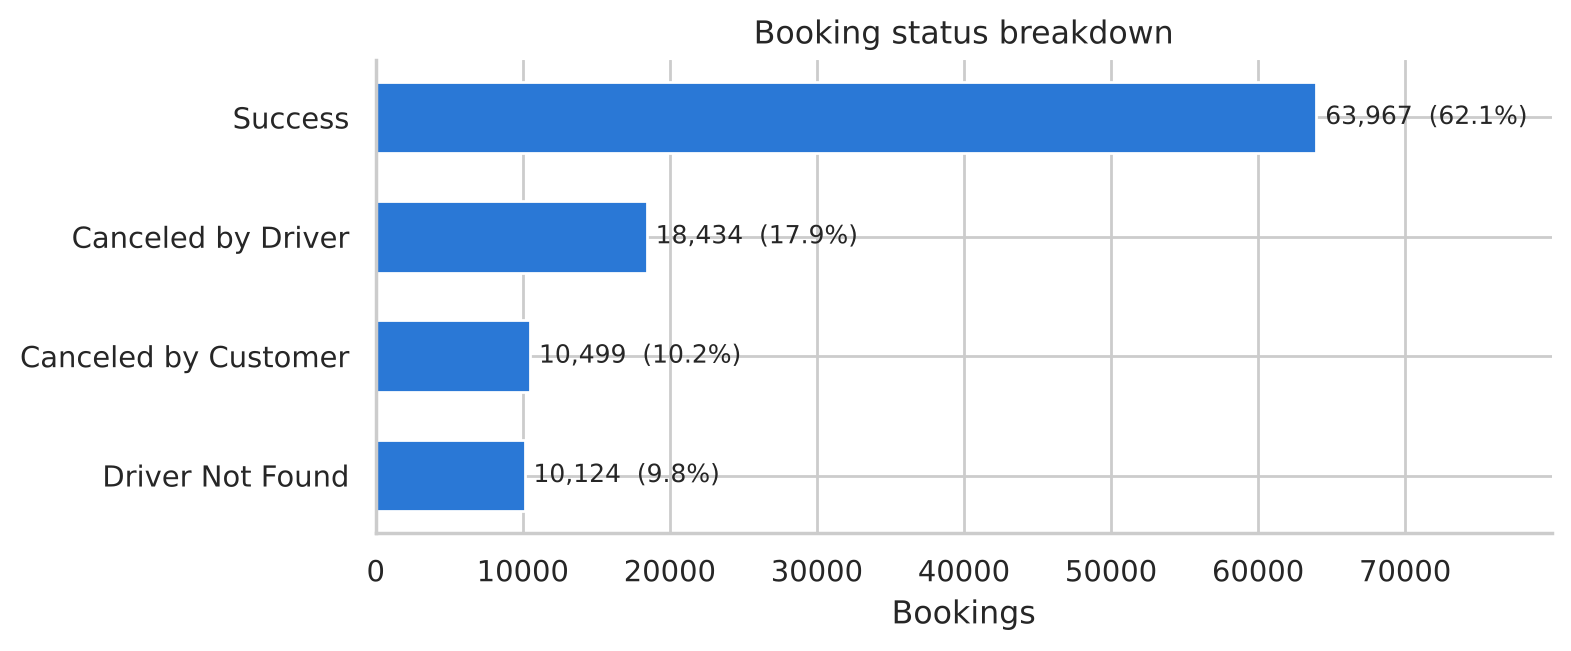

In [11]:
status = df["Booking_Status"].value_counts()
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.barh(status.index[::-1], status.values[::-1], color=BLUE, height=0.6)
for i, v in enumerate(status.values[::-1]):
    ax.text(v + 600, i, f"{v:,}  ({v / len(df):.1%})", va="center", fontsize=9)
ax.set_title("Booking status breakdown")
ax.set_xlabel("Bookings")
ax.set_xlim(0, status.max() * 1.25)
plt.tight_layout(); plt.show()

Only **62.1%** of bookings turn into a ride. Drivers cancel **17.9%** of bookings, almost twice as often as customers (10.2%), and in another **9.8%** no driver was found at all. Close to 28% of demand is lost on the supply side.

## 5. Demand over time

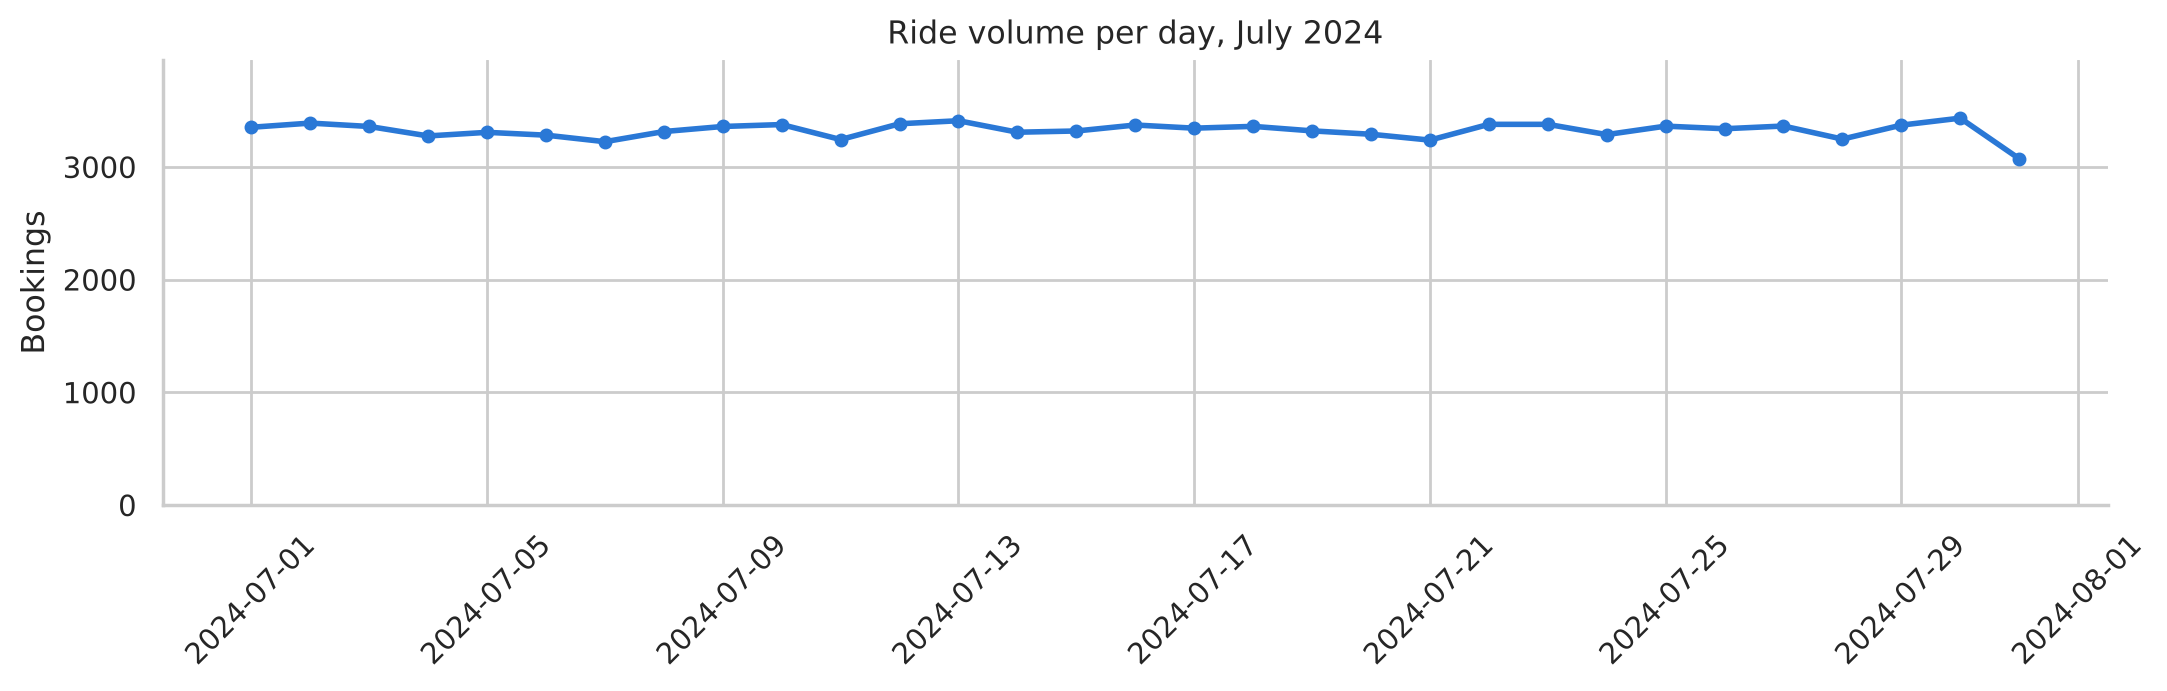

Daily bookings: min 3072 | max 3432 | mean 3323


In [12]:
daily = df.groupby(df["Booking_DateTime"].dt.date).size()
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.plot(daily.index, daily.values, color=BLUE, lw=2, marker="o", ms=4)
ax.set_title("Ride volume per day, July 2024")
ax.set_ylabel("Bookings")
ax.set_ylim(0, daily.max() * 1.15)
plt.xticks(rotation=45); plt.tight_layout(); plt.show()
print("Daily bookings: min", daily.min(), "| max", daily.max(), "| mean", round(daily.mean()))

In [13]:
order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
by_day = df.groupby("Day_Name").agg(bookings=("Booking_ID", "count"),
                                    days=("Ride_Date", "nunique")).reindex(order)
by_day["avg_per_day"] = (by_day["bookings"] / by_day["days"]).round(0)
by_day

,bookings,days,avg_per_day
Day_Name,,,
Monday,16729,5,3346.0
Tuesday,16926,5,3385.0
Wednesday,16434,5,3287.0
Thursday,13236,4,3309.0
Friday,13345,4,3336.0
Saturday,13341,4,3335.0
Sunday,13013,4,3253.0


At first glance Monday to Wednesday look busier, but that is a calendar effect: July 2024 has **five** Mondays, Tuesdays and Wednesdays and only four of the other days. Per day, demand is flat at roughly 3,300 bookings whatever the weekday. Always normalise before calling a "peak".

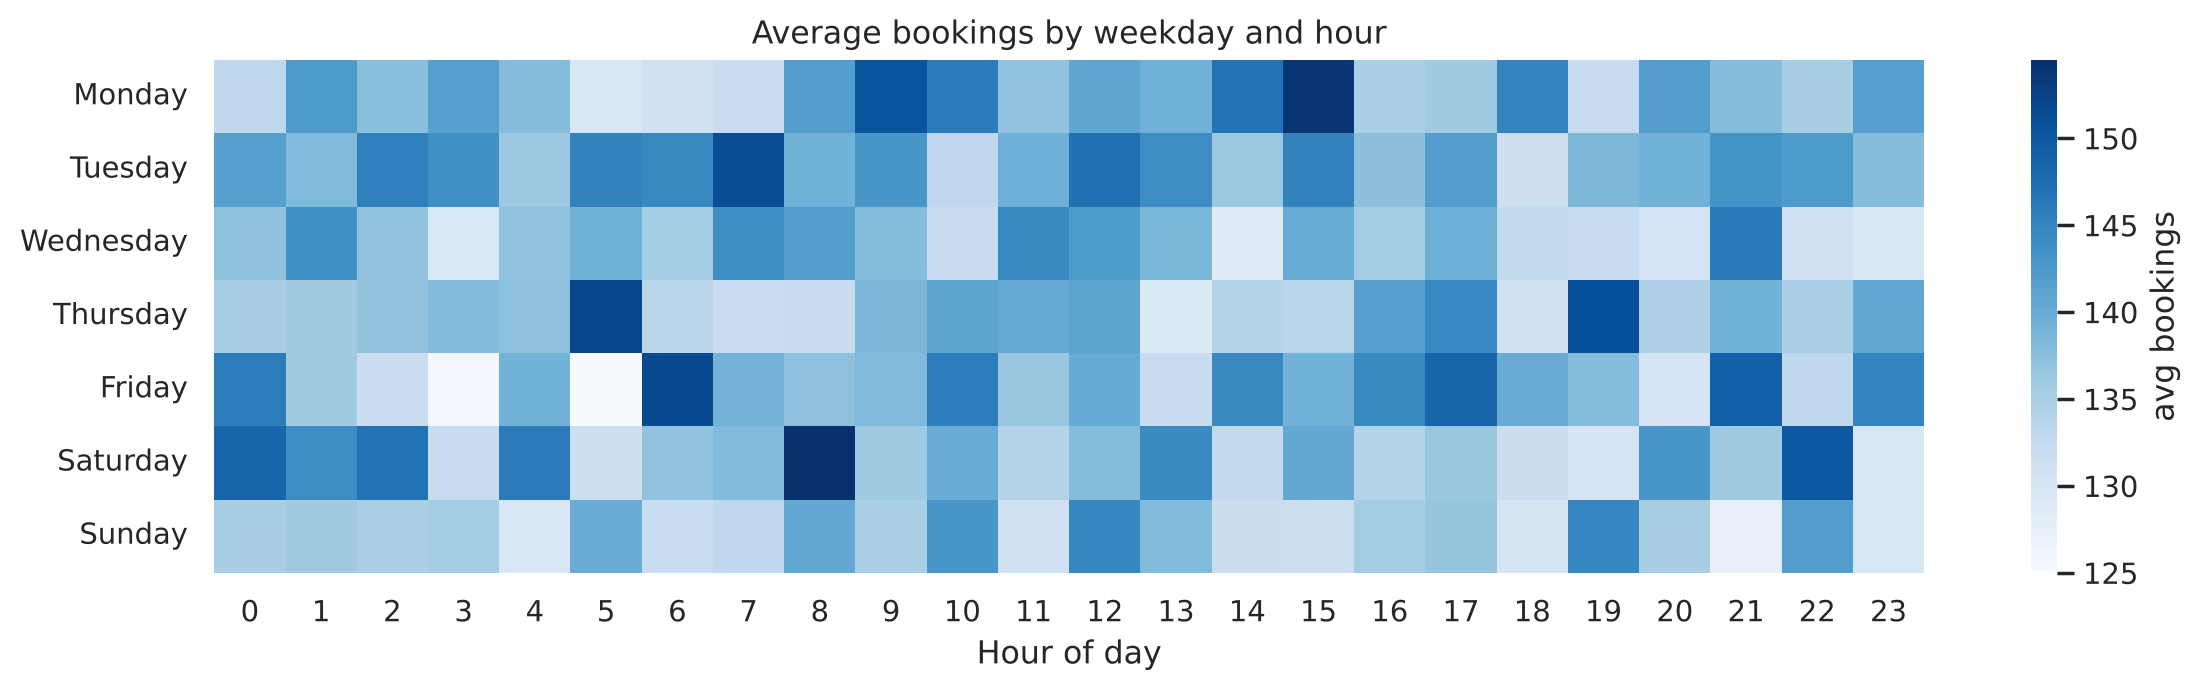

In [14]:
heat = df.pivot_table(index="Day_Name", columns="Ride_Hour", values="Booking_ID", aggfunc="count").reindex(order)
heat = heat.div(by_day["days"], axis=0)   # average bookings per hour slot
fig, ax = plt.subplots(figsize=(12, 3.6))
sns.heatmap(heat, cmap="Blues", ax=ax, cbar_kws={"label": "avg bookings"})
ax.set_title("Average bookings by weekday and hour")
ax.set_xlabel("Hour of day"); ax.set_ylabel("")
plt.tight_layout(); plt.show()

The hour-by-weekday grid has no hot band. Each hour gets roughly 4,200 to 4,400 bookings across the month, so this data has no rush-hour peak. For driver allocation the useful lever is **not** shifting drivers to certain hours but **reducing driver cancellations and 'driver not found' cases in every hour**.

## 6. Vehicle types

In [15]:
veh = success.groupby("Vehicle_Type").agg(
    rides=("Booking_ID", "count"),
    revenue=("Booking_Value", "sum"),
    avg_distance=("Ride_Distance", "mean"),
    avg_fare=("Booking_Value", "mean"),
).sort_values("revenue", ascending=False).round(1)
veh["success_rate_%"] = (df.groupby("Vehicle_Type")["Revenue"].apply(lambda s: (s > 0).mean() * 100)).round(1)
veh

,rides,revenue,avg_distance,avg_fare,success_rate_%
Vehicle_Type,,,,,
Prime Sedan,9379,5224050,25.0,557.0,63.0
E-Bike,9180,5054662,25.1,550.6,62.0
Auto,9167,5051846,10.0,551.1,62.1
Prime Plus,9075,5015165,25.0,552.6,61.7
Bike,9134,4971968,24.9,544.3,62.3
Mini,9036,4885961,25.0,540.7,62.1
Prime SUV,8996,4876815,24.9,542.1,61.4


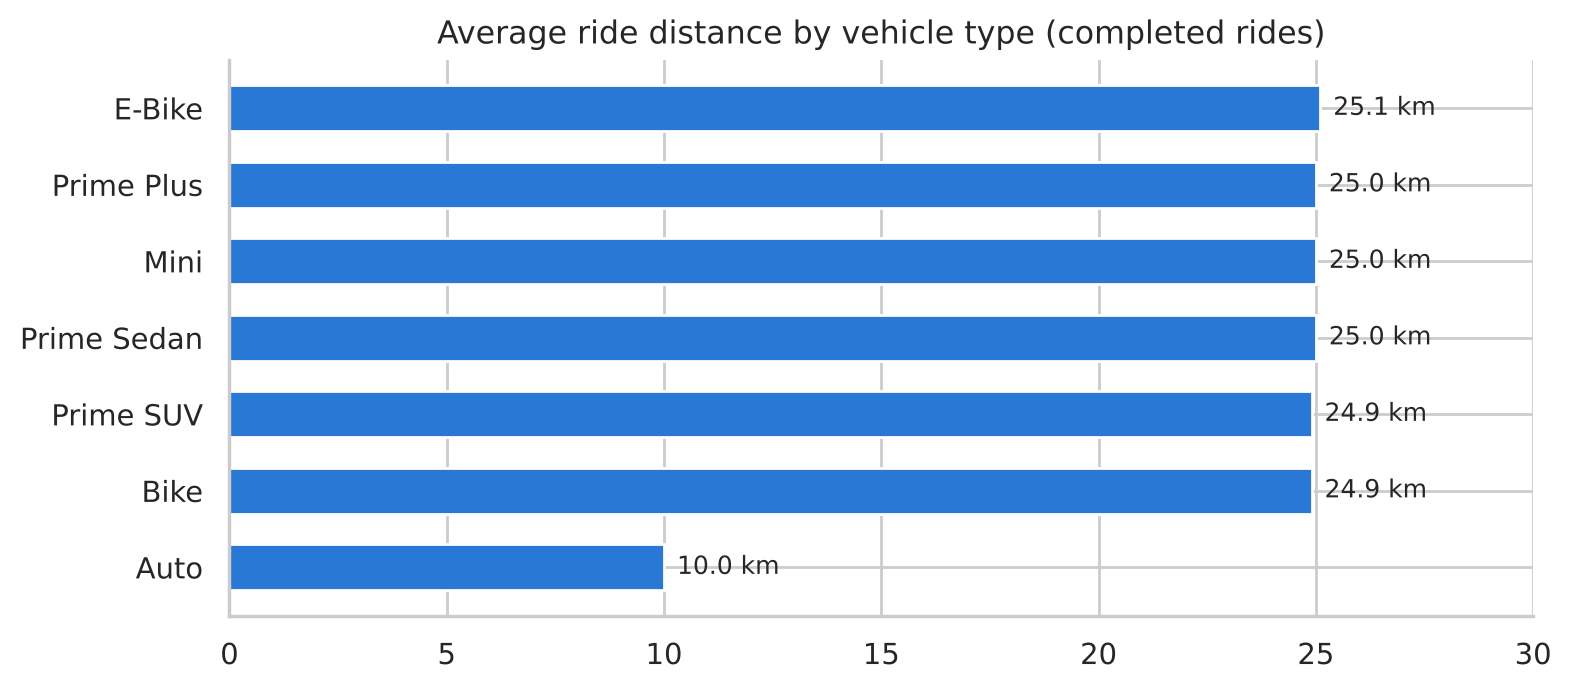

In [16]:
fig, ax = plt.subplots(figsize=(8, 3.6))
v = veh["avg_distance"].sort_values()
ax.barh(v.index, v.values, color=BLUE, height=0.6)
for i, val in enumerate(v.values):
    ax.text(val + 0.3, i, f"{val:.1f} km", va="center", fontsize=9)
ax.set_title("Average ride distance by vehicle type (completed rides)")
ax.set_xlim(0, 30)
plt.tight_layout(); plt.show()

Bookings are spread almost evenly across the seven vehicle types (about 14% each). The one real difference is **Auto**: its rides average about 10 km, against about 25 km for every other type, which fits autos being used for short hops.

## 7. Revenue and payments

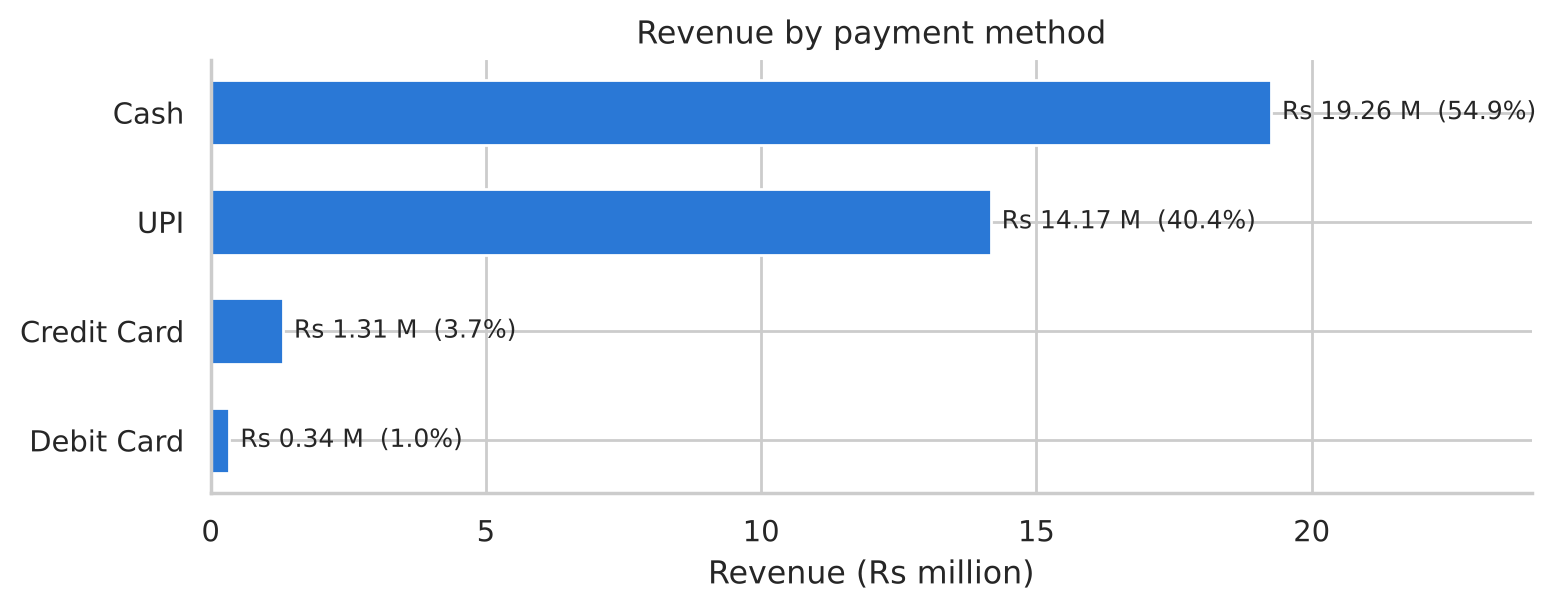

,count,sum,share_%
Payment_Method,,,
Cash,35022,19260316,54.9
UPI,25881,14168436,40.4
Credit Card,2435,1312793,3.7
Debit Card,629,338922,1.0


In [17]:
pay = success.groupby("Payment_Method")["Booking_Value"].agg(["count", "sum"])
pay["share_%"] = (pay["sum"] / pay["sum"].sum() * 100).round(1)
pay = pay.sort_values("sum", ascending=False)
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.barh(pay.index[::-1], pay["sum"][::-1] / 1e6, color=BLUE, height=0.6)
for i, (s, sh) in enumerate(zip(pay["sum"][::-1], pay["share_%"][::-1])):
    ax.text(s / 1e6 + 0.2, i, f"Rs {s/1e6:.2f} M  ({sh}%)", va="center", fontsize=9)
ax.set_title("Revenue by payment method"); ax.set_xlabel("Revenue (Rs million)")
ax.set_xlim(0, 24)
plt.tight_layout(); plt.show()
pay

Cash still brings in **55%** of revenue and UPI **40%**. Cards are under 5% combined.

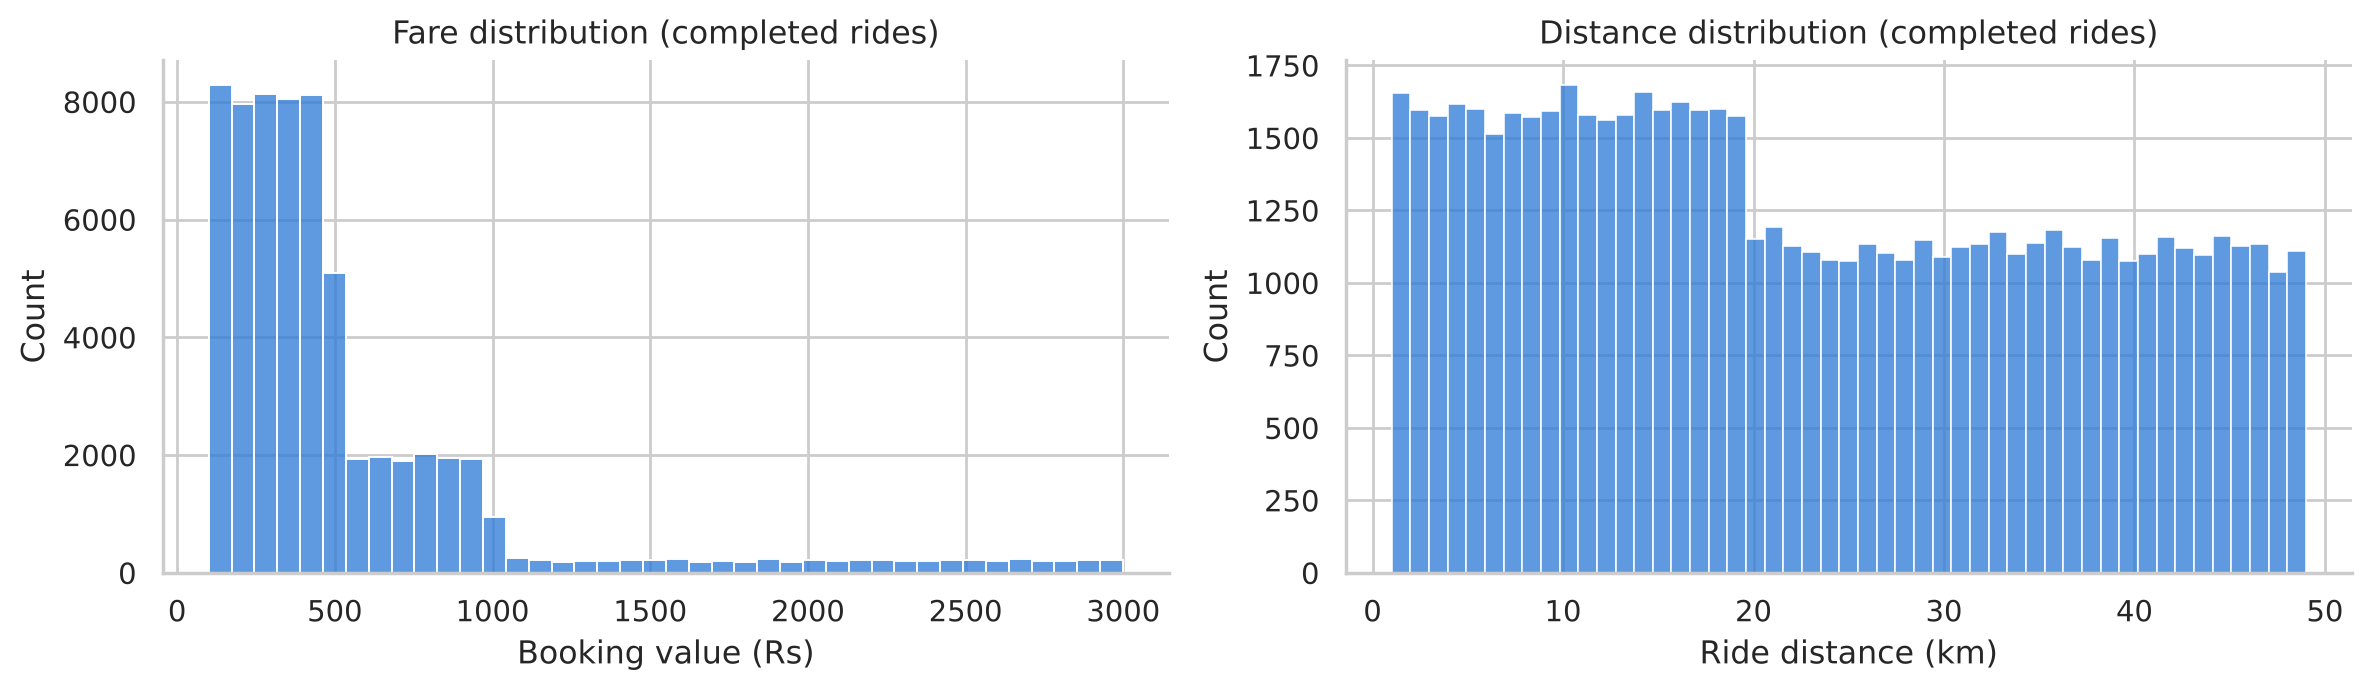

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
sns.histplot(success["Booking_Value"], bins=40, color=BLUE, ax=axes[0])
axes[0].set_title("Fare distribution (completed rides)"); axes[0].set_xlabel("Booking value (Rs)")
sns.histplot(success["Ride_Distance"], bins=49, color=BLUE, ax=axes[1])
axes[1].set_title("Distance distribution (completed rides)"); axes[1].set_xlabel("Ride distance (km)")
plt.tight_layout(); plt.show()

In [19]:
print("Correlation between fare and distance:", round(success["Booking_Value"].corr(success["Ride_Distance"]), 3))
top_cust = success.groupby("Customer_ID")["Booking_Value"].sum().nlargest(5)
top_cust

Correlation between fare and distance: 0.002


Customer_ID
CID836942    6019
CID868113    5986
CID695232    5962
CID176493    5944
CID902403    5938
Name: Booking_Value, dtype: int64

Fares are right-skewed (most rides under Rs 1,000, a long tail to Rs 3,000). The surprise is that **fare has no link to distance** (correlation of 0.002). In a real fare model distance is the main driver. So either a large part of the fare comes from surge or flat pricing, or this is a simulated dataset. I flag it as a pricing question rather than drawing strong conclusions from it.

## 8. Cancellations

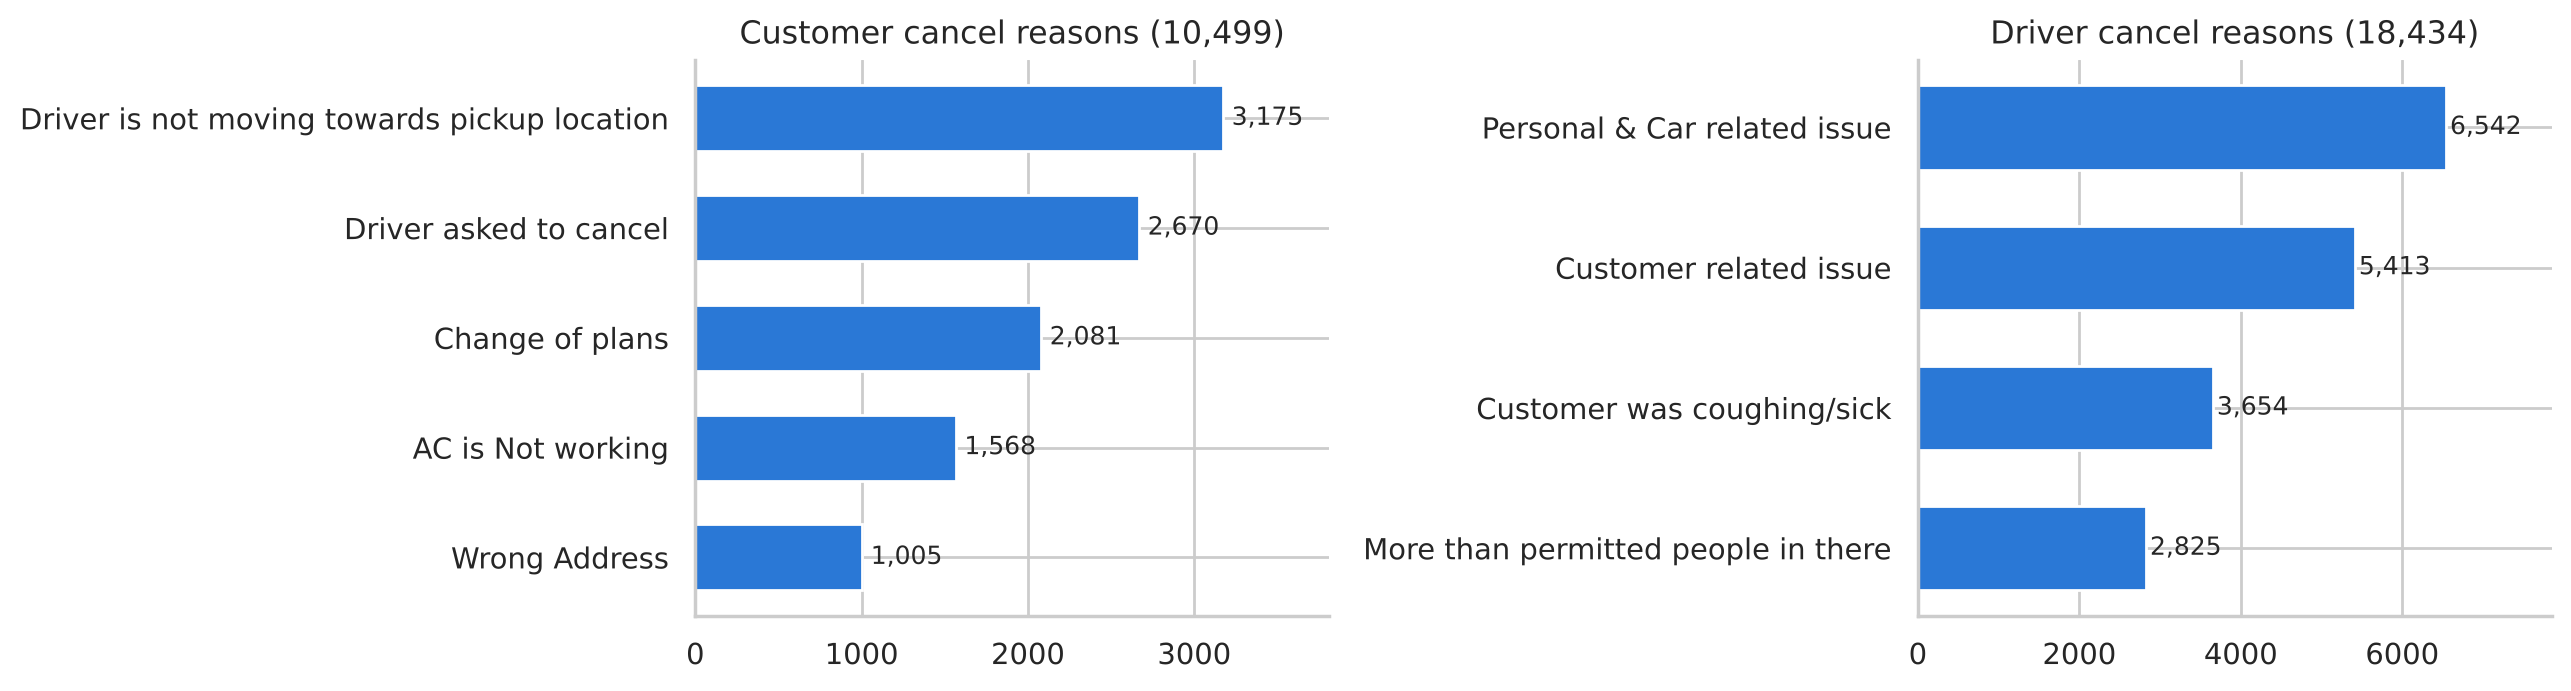

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
c = df["Canceled_Rides_by_Customer"].value_counts().sort_values()
axes[0].barh(c.index, c.values, color=BLUE, height=0.6)
axes[0].set_title(f"Customer cancel reasons ({c.sum():,})")
d = df["Canceled_Rides_by_Driver"].value_counts().sort_values()
axes[1].barh(d.index, d.values, color=BLUE, height=0.6)
axes[1].set_title(f"Driver cancel reasons ({d.sum():,})")
for ax, s in zip(axes, [c, d]):
    for i, v in enumerate(s.values):
        ax.text(v + 50, i, f"{v:,}", va="center", fontsize=9)
    ax.set_xlim(0, s.max() * 1.2)
plt.tight_layout(); plt.show()

- **Customers** mostly cancel because of the driver: *driver not moving towards pickup* (30%) and *driver asked to cancel* (25%). More than half of customer cancellations are really a driver behaviour problem.
- **Drivers** cancel mostly for *personal & car related issues* (35%) and *customer related issues* (29%).
- Incomplete rides (3,926) come from customer demand, vehicle breakdown and other issues.

## 9. Ratings

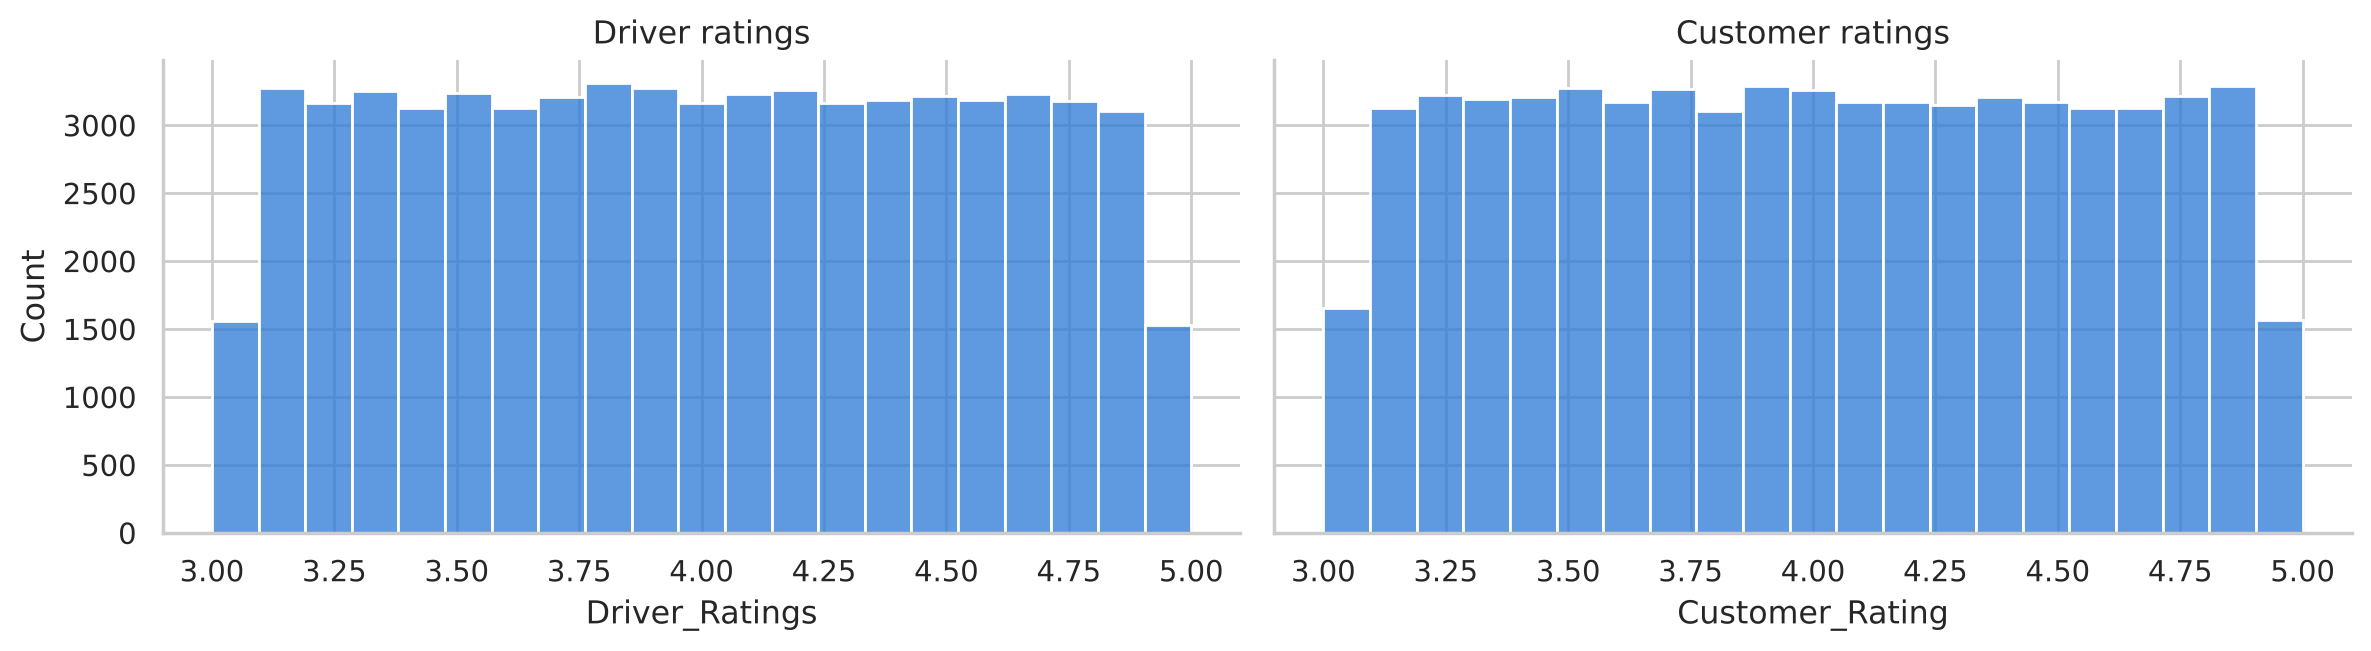

,Driver_Ratings,Customer_Rating
Vehicle_Type,,
Auto,4.00,4.00
Bike,3.98,3.99
E-Bike,4.01,3.99
Mini,3.99,4.00
Prime Plus,4.00,4.01
Prime SUV,4.01,4.00
Prime Sedan,3.99,4.00


In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4), sharey=True)
sns.histplot(success["Driver_Ratings"], bins=21, color=BLUE, ax=axes[0])
axes[0].set_title("Driver ratings")
sns.histplot(success["Customer_Rating"], bins=21, color=BLUE, ax=axes[1])
axes[1].set_title("Customer ratings")
plt.tight_layout(); plt.show()

success.groupby("Vehicle_Type")[["Driver_Ratings", "Customer_Rating"]].mean().round(2)

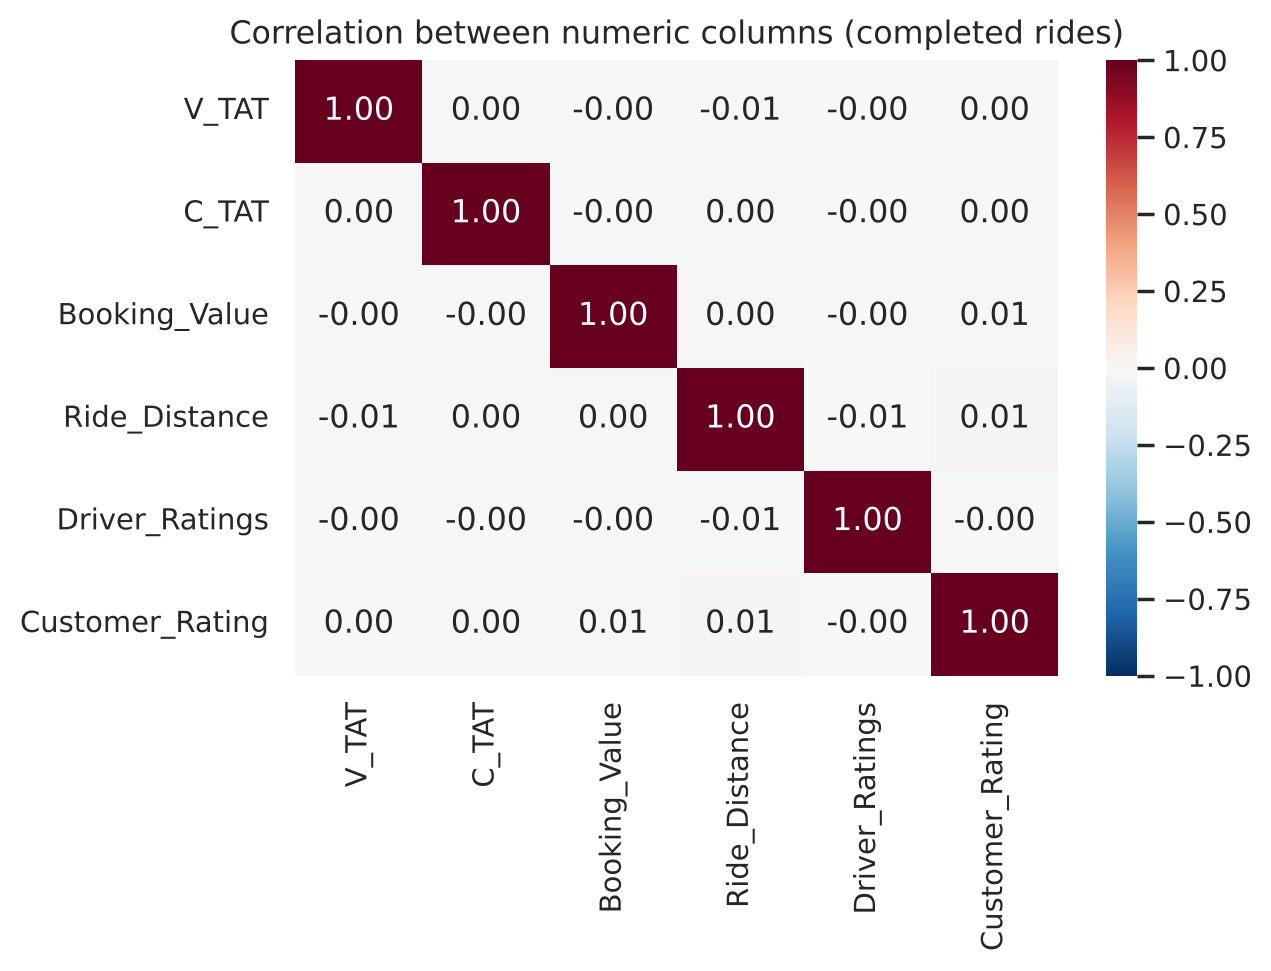

In [22]:
num = success[["V_TAT", "C_TAT", "Booking_Value", "Ride_Distance", "Driver_Ratings", "Customer_Rating"]].astype(float)
fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(num.corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlation between numeric columns (completed rides)")
plt.tight_layout(); plt.show()

Both rating scales sit between 3.0 and 5.0 with an average of 4.0 for every vehicle type. Ratings also have no link to waiting time (V_TAT / C_TAT) or fare. Satisfaction is steady, and nothing in this data shows a group that is clearly unhappier.

## 10. Anomaly and data quality checks

In [23]:
checks = {}
checks["Pickup and drop are the same place"] = (df["Pickup_Location"] == df["Drop_Location"]).sum()
fpk = success["Booking_Value"] / success["Ride_Distance"]
checks["Completed rides charging over Rs 200 per km"] = (fpk > 200).sum()
checks["Rides of 1-2 km costing over Rs 1,500"] = ((success["Ride_Distance"] <= 2) & (success["Booking_Value"] > 1500)).sum()
checks["'Incomplete' rides still marked Success"] = (df["Incomplete_Rides"] == "Yes").sum()
checks["Customers with 2+ bookings on the same day"] = (df.groupby(["Customer_ID", "Ride_Date"]).size() > 1).sum()
pd.Series(checks, name="rows").to_frame()

,rows
Pickup and drop are the same place,2121
Completed rides charging over Rs 200 per km,3591
"Rides of 1-2 km costing over Rs 1,500",221
'Incomplete' rides still marked Success,3926
Customers with 2+ bookings on the same day,206


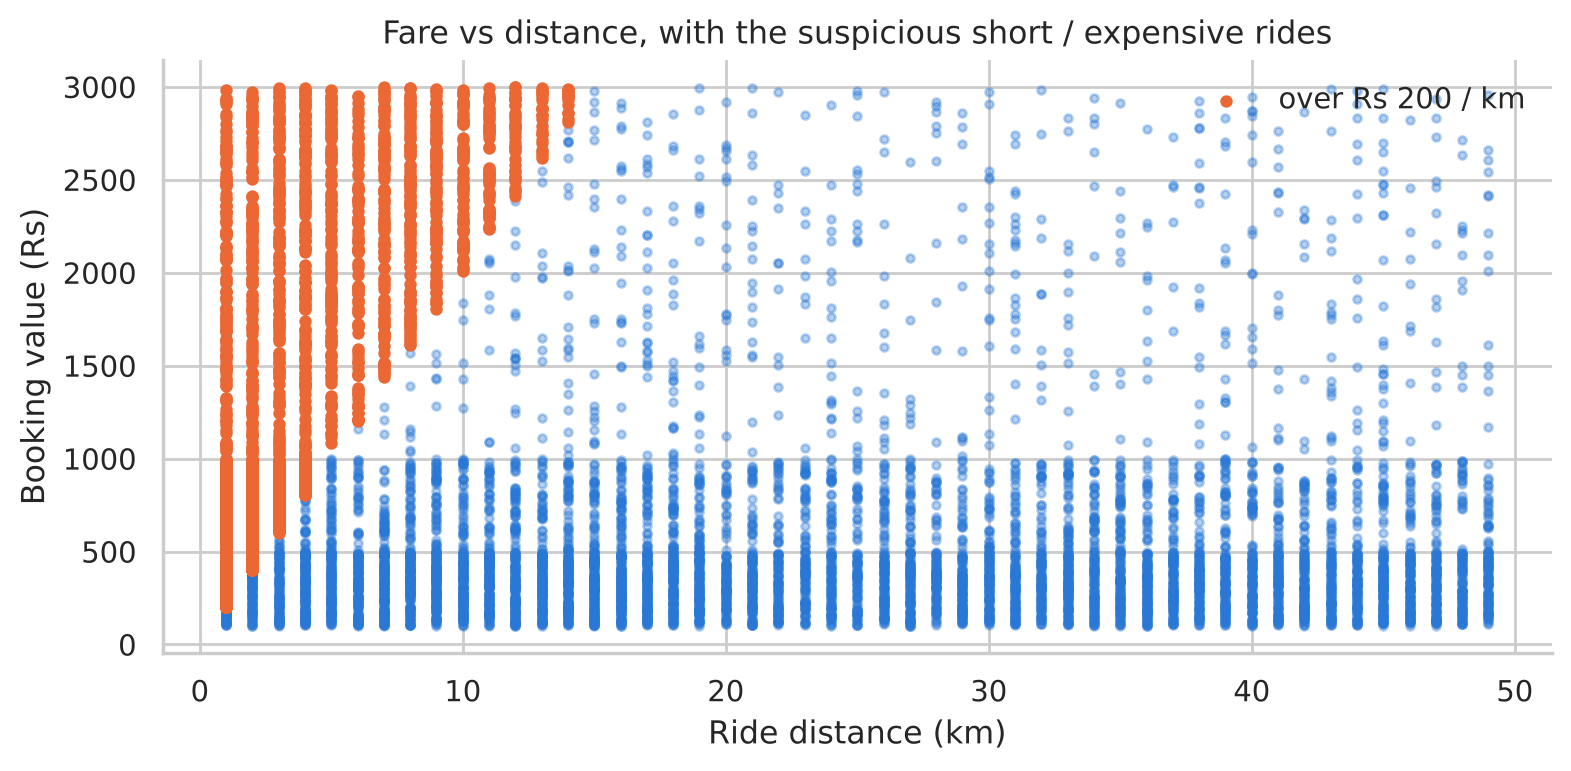

In [24]:
fig, ax = plt.subplots(figsize=(8, 4))
sample = success.sample(8000, random_state=1)
ax.scatter(sample["Ride_Distance"], sample["Booking_Value"], s=8, alpha=0.35, color=BLUE)
flag = success[fpk > 200]
ax.scatter(flag["Ride_Distance"], flag["Booking_Value"], s=12, color="#eb6834", label="over Rs 200 / km")
ax.set_xlabel("Ride distance (km)"); ax.set_ylabel("Booking value (Rs)")
ax.set_title("Fare vs distance, with the suspicious short / expensive rides")
ax.legend(frameon=False)
plt.tight_layout(); plt.show()

Things worth a closer look by an operations or fraud team:

- **2,121 bookings** have the same pickup and drop location.
- **3,591 completed rides** charge more than Rs 200 per km, mostly very short trips with high fares. These are the first candidates for an overcharging or fake-trip check.
- **3,926 rides** are labelled *Success* while the incomplete flag says *Yes*. The status field overstates completed rides, so true completion is 60,041.
- Repeat bookings by the same customer on the same day are rare (206), so there is no sign of booking spam.

## 11. Summary of insights

| Area | Finding | What to do |
|---|---|---|
| Overall | 62.1% success rate, Rs 35.08 M revenue from 63,967 rides | Track success rate as the main health KPI |
| Supply | Drivers cancel 17.9% and no driver is found for 9.8% | Driver incentives for acceptance, penalties for late cancels |
| Demand timing | Flat across hours and weekdays once normalised | Keep driver supply even. Fix cancellations rather than chase peaks |
| Customers | Over half of customer cancels blame the driver | Live ETA alerts when a driver is not moving, faster re-matching |
| Vehicles | Even demand, Auto rides are ~10 km vs ~25 km | Price and promote Auto for short trips |
| Payments | Cash 55%, UPI 40%, cards under 5% | UPI cashback to move riders off cash |
| Pricing | Fare does not follow distance | Review the fare model and surge rules |
| Anomalies | Same pickup/drop, Rs 200+/km rides, "Success" but incomplete | Automated flags for review |